# Supplementary Fig. S11 (label fig:ide): profile-likelihood identifiability

for the leader-follower game model  
(matches the calibration in Fig5_calibration_monoculture_and_coculture_fits.m)  
  
Figure ID1  Monocultures: alpha (leaders) and delta (followers), untreated and +TGF-beta1.  
            Model y(t) = y0*exp(r t); y0 is a nuisance parameter bounded by the  
            data range (as in the calibration). Fitted to all 5 replicates.  
Figure ID2  Co-culture, case H0 (beta, gamma shared by both conditions), joint fit of  
            all six co-cultures (1:1, 1:2, 1:5 L:F; untreated and +TGF-beta1),  
            leader fraction x(t) and N/N0 together, alpha and delta fixed.  
            A: profile of beta, B: profile of gamma, C: bivariate (beta, gamma) surface.  
Figure ID3  The other three cases, written with the TGF-beta1 effects  
            dbeta = beta_TGF - beta_untreated and dgamma = gamma_TGF - gamma_untreated:  
            A: dbeta under H_beta, B: dgamma under H_gamma,  
            C: dbeta and D: dgamma under H_beta_gamma (both change).  
            A profile CI that contains 0 means the data do not require a TGF-beta1 effect.  
  
Likelihood: Gaussian with the variance profiled out,  
    logL = -n/2 * (1 + log(2 pi) + log(SSE/n)),  
with residuals of x and N/N0 divided by their pooled SD (same weighting as the fit).  
95% CI: Delta logL > -chi2_{0.95,1}/2 = -1.92 (one parameter);  
joint 95% region in ID2C: Delta logL > -chi2_{0.95,2}/2 = -3.00.

In [1]:
%matplotlib inline

In [2]:
import os
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.optimize import minimize
from scipy.stats import chi2

OUT = os.path.join(os.path.dirname(os.path.abspath(__file__)) if "__file__" in globals() else ".", "..", "figures")
FIG_NAME = "FigS11_identifiability"

# -------------------------------------------------------------------------
# Fixed growth rates: read the calibration if available, else typed values
# -------------------------------------------------------------------------
ALPHA = np.array([0.3792, 0.1212])   # leaders: untreated, +TGF-beta1
DELTA = np.array([0.4470, 0.4470])   # followers: shared
if os.path.isfile("calibrated_params.mat"):
    from scipy.io import loadmat
    cal = loadmat("calibrated_params.mat")
    ALPHA = np.ravel(cal["alphaFix"]).astype(float)
    DELTA = np.ravel(cal["deltaFix"]).astype(float)
    print("Loaded calibrated_params.mat")
print(f"alpha = {ALPHA}, delta = {DELTA}")

# -------------------------------------------------------------------------
# Data
# -------------------------------------------------------------------------
t_obs = np.arange(5.0)

MONO = {  # normalized N/N0, rows = days 0-4, columns = 5 replicates
    ("Leaders", 0): [[1, 1, 1, 1, 1],
                     [2.3510, 2.4155, 1.1853, 1.2026, 2.1348],
                     [3.0204, 3.2785, 2.8707, 3.0000, 2.8090],
                     [4.5306, 5.9361, 3.6293, 4.2716, 3.5955],
                     [6.8163, 6.4840, 5.5603, 5.9052, 4.4944]],
    ("Leaders", 1): [[1, 1, 1, 1, 1],
                     [0.8143, 0.7173, 1.7026, 1.7974, 1.4607],
                     [1.4051, 0.8342, 2.2586, 2.3147, 1.6854],
                     [0.6257, 0.9541, 2.0560, 2.3534, 1.7978],
                     [1.0212, 1.0425, 2.7026, 2.4828, 1.9101]],
    ("Followers", 0): [[1, 1, 1, 1, 1],
                       [1.2577, 1.5942, 1.5055, 1.5240, 1.8333],
                       [1.7298, 1.0526, 1.2362, 1.1107, 2.7500],
                       [3.5769, 2.8321, 3.8376, 3.8376, 4.1667],
                       [6.6000, 4.9861, 6.7159, 6.3100, 6.6667]],
    ("Followers", 1): [[1, 1, 1, 1, 1],
                       [1.7077, 0.9530, 0.9041, 0.9041, 1.7500],
                       [1.3154, 0.9372, 1.2362, 1.2694, 2.6667],
                       [4.0192, 3.0511, 3.2657, 3.2030, 3.8333],
                       [4.7731, 3.5365, 6.2362, 6.4945, 6.5000]],
}
MONO = {k: np.array(v, float) for k, v in MONO.items()}

# co-cultures: (condition 0/1, leaders, total)
CO = [
    (0, [4.5e5, 7.6e5, 9.0e5, 1.0e6, 9.4e5], [8.7e5, 1.7e6, 2.7e6, 3.4e6, 4.3e6]),  # 1:1
    (0, [3.6e5, 6.2e5, 5.8e5, 6.5e5, 6.4e5], [1.0e6, 2.0e6, 2.8e6, 3.8e6, 5.3e6]),  # 1:2
    (0, [1.8e5, 2.7e5, 2.6e5, 3.3e5, 4.0e5], [9.9e5, 1.9e6, 3.0e6, 4.4e6, 7.3e6]),  # 1:5
    (1, [4.5e5, 8.1e5, 7.8e5, 6.6e5, 5.3e5], [8.7e5, 1.9e6, 2.5e6, 2.8e6, 3.5e6]),
    (1, [3.6e5, 5.4e5, 5.5e5, 5.5e5, 4.3e5], [1.0e6, 2.0e6, 3.0e6, 4.0e6, 5.7e6]),
    (1, [1.8e5, 2.6e5, 2.4e5, 2.7e5, 2.3e5], [9.9e5, 2.0e6, 3.0e6, 4.4e6, 6.7e6]),
]
COND = np.array([c for c, _, _ in CO])
X_OBS = np.array([np.array(L) / np.array(N) for _, L, N in CO])        # 6 x 5
N_OBS = np.array([np.array(N) / N[0] for _, _, N in CO])               # 6 x 5
X0 = X_OBS[:, 0]
W = np.array([X_OBS[:, 1:].std(), N_OBS[:, 1:].std()])                 # pooled SDs
N_RES = 2 * X_OBS[:, 1:].size                                           # 48

CUT1 = -chi2.ppf(0.95, 1) / 2
CUT2 = -chi2.ppf(0.95, 2) / 2


def gauss_ll(sse, n):
    return -0.5 * n * (1 + np.log(2 * np.pi) + np.log(sse / n))

alpha = [0.3792 0.1212], delta = [0.447 0.447]


## Monocultures

In [3]:
# =========================================================================
# Monocultures
# =========================================================================
def mono_ll(r, y0, T):
    pred = y0 * np.exp(r * t_obs)[:, None]
    return gauss_ll(np.sum((T - pred) ** 2), T.size)


def mono_profile(T, n_grid=81):
    lo, hi = T.min(), T.max()
    best_y0 = lambda r: minimize(lambda v: -mono_ll(r, v[0], T), [1.0],
                                 bounds=[(lo, hi)], method="L-BFGS-B").x[0]
    res = minimize(lambda p: -mono_ll(p[0], p[1], T), [0.4, 1.0],
                   bounds=[(0, 1), (lo, hi)], method="L-BFGS-B",
                   options={"ftol": 1e-14})
    r_hat, ll_hat = res.x[0], -res.fun
    grid = np.linspace(max(0, r_hat - 0.2), min(1, r_hat + 0.2), n_grid)
    prof = np.array([mono_ll(r, best_y0(r), T) for r in grid]) - ll_hat
    return r_hat, grid, prof

## Co-culture model: all six series integrated together

In [4]:
# =========================================================================
# Co-culture model: all six series integrated together
# =========================================================================
def simulate(bC, gC, bT, gT, t_eval=t_obs):
    al = ALPHA[COND]; de = DELTA[COND]
    be = np.where(COND == 0, bC, bT); ga = np.where(COND == 0, gC, gT)

    def rhs(_, z):
        x, n = z[:6], z[6:]
        A = al * x + be * (1 - x)
        B = ga * x + de * (1 - x)
        return np.concatenate([(A - B) * x * (1 - x), (A * x + B * (1 - x)) * n])

    sol = solve_ivp(rhs, (t_eval[0], t_eval[-1]), np.concatenate([X0, np.ones(6)]),
                    t_eval=t_eval, method="LSODA", rtol=1e-8, atol=1e-10)
    if not sol.success:
        return None, None
    return sol.y[:6], sol.y[6:]


# cases written as theta = [beta, gamma, dbeta, dgamma]; free entries per case
CASES = {"H0": [0, 1], "Hbeta": [0, 1, 2], "Hgamma": [0, 1, 3], "Hboth": [0, 1, 2, 3]}
NAMES = ["beta", "gamma", "dbeta", "dgamma"]
BOUNDS = [(-1, 2), (-1, 2), (-1, 1), (-1, 1)]


def co_ll(theta):
    b, g, db, dg = theta
    x, n = simulate(b, g, b + db, g + dg)
    if x is None or not np.all(np.isfinite(x)):
        return -1e10
    r = np.concatenate([((x - X_OBS)[:, 1:] / W[0]).ravel(),
                        ((n - N_OBS)[:, 1:] / W[1]).ravel()])
    return gauss_ll(np.sum(r ** 2), N_RES)


def fit_case(case, fixed=None, start=None):
    """Maximize logL over the free parameters of a case; `fixed` = {index: value}."""
    fixed = fixed or {}
    free = [i for i in CASES[case] if i not in fixed]
    theta = np.zeros(4)
    for i, v in fixed.items():
        theta[i] = v
    x0 = start if start is not None else np.array([0.12, 0.77, 0.0, 0.0])[free]

    def nll(p):
        th = theta.copy(); th[free] = p
        return -co_ll(th)

    res = minimize(nll, x0, method="Nelder-Mead",
                   options={"xatol": 1e-7, "fatol": 1e-9, "maxiter": 4000})
    th = theta.copy(); th[free] = res.x
    return th, -res.fun, res.x


def std_errors(case, theta_hat, h=1e-4):
    """Approximate SEs from a finite-difference Hessian (for choosing grid ranges)."""
    free = CASES[case]
    k = len(free); H = np.zeros((k, k))
    f = lambda th: -co_ll(th)
    for a in range(k):
        for b in range(a, k):
            def shifted(sa, sb):
                th = theta_hat.copy(); th[free[a]] += sa * h; th[free[b]] += sb * h
                return f(th)
            H[a, b] = H[b, a] = (shifted(1, 1) - shifted(1, -1) - shifted(-1, 1) + shifted(-1, -1)) / (4 * h * h)
    return dict(zip(free, np.sqrt(np.abs(np.diag(np.linalg.inv(H))))))


def co_profile(case, idx, theta_hat, ll_hat, se, width=4.0, n_grid=41):
    lo = max(BOUNDS[idx][0], theta_hat[idx] - width * se)
    hi = min(BOUNDS[idx][1], theta_hat[idx] + width * se)
    grid = np.linspace(lo, hi, n_grid)
    prof = np.full(n_grid, np.nan)
    free = [i for i in CASES[case] if i != idx]
    start_idx = int(np.argmin(np.abs(grid - theta_hat[idx])))
    for direction in (range(start_idx, n_grid), range(start_idx - 1, -1, -1)):
        warm = theta_hat[free].copy()
        for j in direction:
            _, ll, warm = fit_case(case, fixed={idx: grid[j]}, start=warm)
            prof[j] = ll
    return grid, prof - ll_hat


def profile_ci(grid, prof, cut=CUT1):
    """Interpolated parameter values where the profile crosses the cutoff."""
    inside = prof >= cut
    if not inside.any():
        return np.nan, np.nan
    i0, i1 = np.where(inside)[0][[0, -1]]
    lo = np.interp(cut, [prof[i0 - 1], prof[i0]], [grid[i0 - 1], grid[i0]]) if i0 > 0 else -np.inf
    hi = np.interp(cut, [prof[i1 + 1], prof[i1]], [grid[i1 + 1], grid[i1]]) if i1 < len(grid) - 1 else np.inf
    return lo, hi

## Plot style (as in the other figures)

In [5]:
# =========================================================================
# Plot style (as in the other figures)
# =========================================================================
plt.rcParams.update({"font.family": "sans-serif",
                     "font.sans-serif": ["Helvetica", "Arial", "DejaVu Sans"],
                     "axes.spines.top": False, "axes.spines.right": False})
LABEL_FS, TICK_FS, LEGEND_FS, PANEL_FS, TITLE_FS = 18, 13, 12, 20, 15


def profile_panel(ax, grid, prof, p_hat, xlabel, letter, title=None, zero_line=False):
    ax.plot(grid, prof, color="black", lw=3, label="Profile")
    ax.plot(grid, prof, "ro", ms=3, alpha=0.5, markeredgecolor="black")
    ax.axhline(CUT1, color="g", lw=2, ls="-.", label="95% CI")
    ax.axvline(p_hat, color="m", lw=2, ls="--", label="MLE")
    if zero_line:
        ax.axvline(0, color="0.4", lw=1.5, ls=":", label="No TGF-$\\beta$1 effect")
    lo, hi = profile_ci(grid, prof)
    ax.set_ylim(-8, 0.4)                       # same zoom in every panel: the 95% cutoff is at -1.92
    ax.set_xlabel(xlabel, fontsize=LABEL_FS)
    ax.set_ylabel(r"$\Delta$ log-likelihood", fontsize=LABEL_FS - 1)
    ax.tick_params(labelsize=TICK_FS)
    ax.grid(True, alpha=0.3)
    if title:
        ax.set_title(title, fontsize=TITLE_FS, fontweight="bold")
    ax.text(-0.18, 1.04, letter, transform=ax.transAxes, fontsize=PANEL_FS,
            fontweight="bold", va="bottom", ha="left")
    return lo, hi


summary = []
from matplotlib.lines import Line2D

## Compute all profiles

Profiling monocultures ...


Fitting co-culture case H0 ...
  beta = 0.1235, gamma = 0.7657, logL = -13.4704
  profiling beta ...


  profiling gamma ...


  bivariate (beta, gamma) surface ...


Fitting co-culture case Hbeta ...


  profiling dbeta ...


... (3 outputs left out)

  profiling dbeta ...


  profiling dgamma ...


Saved ./../figures/FigS11_identifiability.pdf


Saved ./../figures/FigS11_identifiability.png

================ Profile-likelihood 95% CIs ================
Dataset                      parameter       MLE   95% CI
Leaders, untreated           alpha        0.3796   [0.3171, 0.4481]
Leaders, +TGF-beta1          alpha        0.1247   [0.0192, 0.2377]
Followers, untreated         delta        0.4475   [0.4136, 0.4678]
Followers, +TGF-beta1        delta        0.4453   [0.3900, 0.4713]
Co-culture H0                beta         0.1235   [0.0688, 0.1751]
Co-culture H0                gamma        0.7657   [0.6938, 0.8388]
Co-culture Hbeta             dbeta       -0.0157   [-0.1253, 0.0915]
Co-culture Hgamma            dgamma       0.0161   [-0.1299, 0.1623]
Co-culture Hboth             dbeta       -0.0161   [-0.1257, 0.0911]
Co-culture Hboth             dgamma       0.0168   [-0.1295, 0.1637]


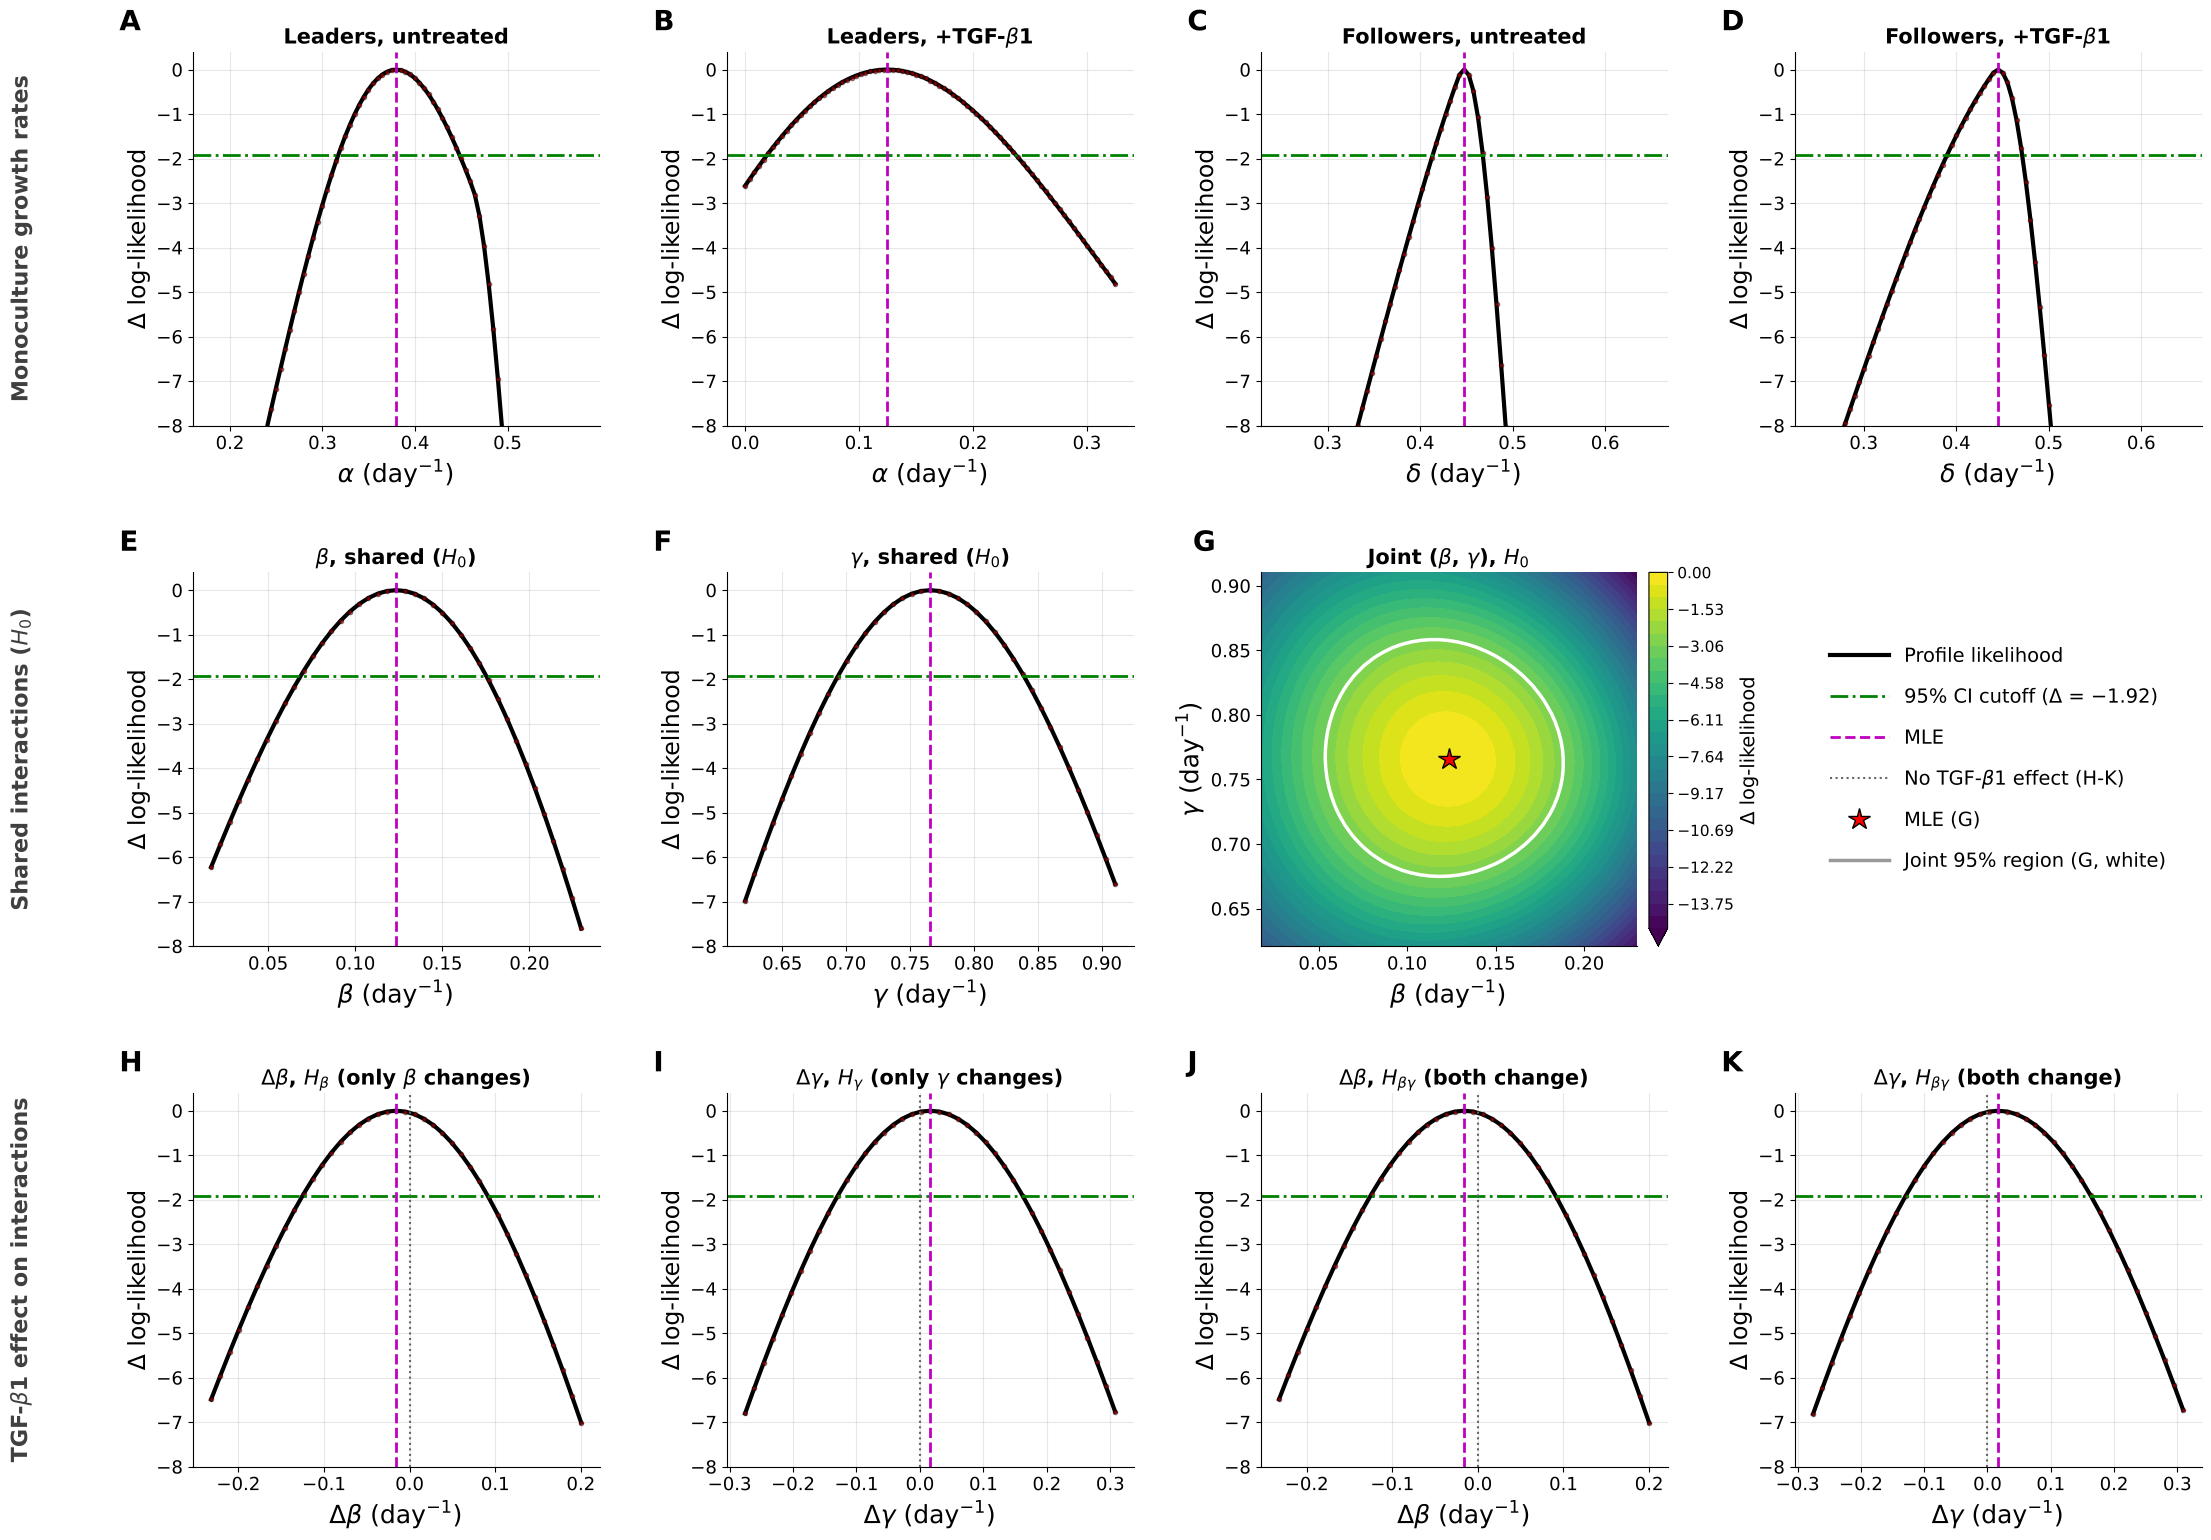

In [6]:
# =========================================================================
# Compute all profiles
# =========================================================================
mono_res = []
mono_panels = [(("Leaders", 0), r"$\alpha$ (day$^{-1}$)", "Leaders, untreated", "alpha"),
               (("Leaders", 1), r"$\alpha$ (day$^{-1}$)", "Leaders, +TGF-$\\beta$1", "alpha"),
               (("Followers", 0), r"$\delta$ (day$^{-1}$)", "Followers, untreated", "delta"),
               (("Followers", 1), r"$\delta$ (day$^{-1}$)", "Followers, +TGF-$\\beta$1", "delta")]
print("Profiling monocultures ...")
for key, xl, title, pname in mono_panels:
    mono_res.append(mono_profile(MONO[key]))

print("Fitting co-culture case H0 ...")
th0, ll0, _ = fit_case("H0")
se0 = std_errors("H0", th0)
print(f"  beta = {th0[0]:.4f}, gamma = {th0[1]:.4f}, logL = {ll0:.4f}")
h0_res = []
for idx in (0, 1):
    print(f"  profiling {NAMES[idx]} ...")
    h0_res.append(co_profile("H0", idx, th0, ll0, se0[idx]))
print("  bivariate (beta, gamma) surface ...")
bg = np.linspace(th0[0] - 4 * se0[0], th0[0] + 4 * se0[0], 41)
gg = np.linspace(th0[1] - 4 * se0[1], th0[1] + 4 * se0[1], 41)
LL = np.array([[co_ll([b, g, 0, 0]) for b in bg] for g in gg]) - ll0

jobs = [("Hbeta", 2, r"$\Delta\beta$ (day$^{-1}$)", r"$\Delta\beta$, $H_\beta$ (only $\beta$ changes)"),
        ("Hgamma", 3, r"$\Delta\gamma$ (day$^{-1}$)", r"$\Delta\gamma$, $H_\gamma$ (only $\gamma$ changes)"),
        ("Hboth", 2, r"$\Delta\beta$ (day$^{-1}$)", r"$\Delta\beta$, $H_{\beta\gamma}$ (both change)"),
        ("Hboth", 3, r"$\Delta\gamma$ (day$^{-1}$)", r"$\Delta\gamma$, $H_{\beta\gamma}$ (both change)")]
fits, tgf_res = {}, []
for case, idx, xl, title in jobs:
    if case not in fits:
        print(f"Fitting co-culture case {case} ...")
        th, ll, _ = fit_case(case)
        fits[case] = (th, ll, std_errors(case, th))
    th, ll, se = fits[case]
    print(f"  profiling {NAMES[idx]} ...")
    tgf_res.append((th[idx],) + co_profile(case, idx, th, ll, se[idx]))

# =========================================================================
# One figure, 3 rows x 4 columns
#   Row 1 (A-D): monoculture growth rates alpha, delta
#   Row 2 (E-G): shared interactions beta, gamma and their joint region; legend
#   Row 3 (H-K): TGF-beta1 effects on the interactions in the other three cases
# =========================================================================
fig, axes = plt.subplots(3, 4, figsize=(22, 15.5))
letters = iter("ABCDEFGHIJK")

for ax, (key, xl, title, pname), (r_hat, grid, prof) in zip(axes[0], mono_panels, mono_res):
    lo, hi = profile_panel(ax, grid, prof, r_hat, xl, next(letters), title)
    summary.append((title.replace("$\\beta$", "beta"), pname, r_hat, lo, hi))

for ax, idx, (grid, prof) in zip(axes[1, :2], (0, 1), h0_res):
    sym = r"$\beta$" if idx == 0 else r"$\gamma$"
    lo, hi = profile_panel(ax, grid, prof, th0[idx], sym + " (day$^{-1}$)", next(letters),
                           sym + r", shared ($H_0$)")
    summary.append(("Co-culture H0", NAMES[idx], th0[idx], lo, hi))

ax = axes[1, 2]
cf = ax.contourf(bg, gg, LL, levels=np.linspace(max(LL.min(), -20), 0, 30),
                 cmap="viridis", extend="min")
cb = fig.colorbar(cf, ax=ax, fraction=0.046, pad=0.03)
cb.set_label(r"$\Delta$ log-likelihood", fontsize=TICK_FS + 1)
cb.ax.tick_params(labelsize=TICK_FS - 2)
ax.contour(bg, gg, LL, levels=[CUT2], colors="white", linewidths=2.5, linestyles="solid")
ax.plot(th0[0], th0[1], "r*", ms=16, mec="k")
ax.set_xlabel(r"$\beta$ (day$^{-1}$)", fontsize=LABEL_FS)
ax.set_ylabel(r"$\gamma$ (day$^{-1}$)", fontsize=LABEL_FS)
ax.set_title(r"Joint ($\beta$, $\gamma$), $H_0$", fontsize=TITLE_FS, fontweight="bold")
ax.tick_params(labelsize=TICK_FS)
ax.text(-0.18, 1.04, next(letters), transform=ax.transAxes, fontsize=PANEL_FS,
        fontweight="bold", va="bottom", ha="left")

# legend in the free slot (row 2, column 4)
lax = axes[1, 3]; lax.axis("off")
handles = [Line2D([], [], color="black", lw=3, label="Profile likelihood"),
           Line2D([], [], color="g", lw=2, ls="-.", label="95% CI cutoff ($\\Delta$ = $-1.92$)"),
           Line2D([], [], color="m", lw=2, ls="--", label="MLE"),
           Line2D([], [], color="0.4", lw=1.5, ls=":", label="No TGF-$\\beta$1 effect (H-K)"),
           Line2D([], [], color="r", marker="*", ms=16, mec="k", ls="none", label="MLE (G)"),
           Line2D([], [], color="0.6", lw=2.5, label="Joint 95% region (G, white)")]
lax.legend(handles=handles, loc="center", fontsize=LEGEND_FS + 2, frameon=False,
           handlelength=3, labelspacing=1.1)

for ax, (case, idx, xl, title), (p_hat, grid, prof) in zip(axes[2], jobs, tgf_res):
    lo, hi = profile_panel(ax, grid, prof, p_hat, xl, next(letters), title, zero_line=True)
    summary.append((f"Co-culture {case}", NAMES[idx], p_hat, lo, hi))

# row headers on the left margin
for row, text in enumerate(["Monoculture growth rates",
                            "Shared interactions ($H_0$)",
                            "TGF-$\\beta$1 effect on interactions"]):
    axes[row, 0].annotate(text, xy=(-0.42, 0.5), xycoords="axes fraction", rotation=90,
                          ha="center", va="center", fontsize=TITLE_FS + 1, fontweight="bold",
                          color="0.25")

fig.tight_layout(w_pad=2.5, h_pad=3.0)
fig.subplots_adjust(left=0.08)
os.makedirs(OUT, exist_ok=True)
for ext in ("pdf", "png"):
    path = os.path.join(OUT, f"{FIG_NAME}.{ext}")
    fig.savefig(path, dpi=300, bbox_inches="tight")
    print(f"Saved {path}")

# ---------------- Summary ----------------
print("\n================ Profile-likelihood 95% CIs ================")
print(f"{'Dataset':28s} {'parameter':10s} {'MLE':>8s}   95% CI")
for name, p, est, lo, hi in summary:
    print(f"{name:28s} {p:10s} {est:8.4f}   [{lo:.4f}, {hi:.4f}]")

plt.show()